# Phase27 - Multi-Domain Performance Preservation Audit
## Canonical execution on the VAL808 continuity development benchmark

**Classification:** `PHASE27_CANONICAL_MULTIDOMAIN_PRESERVATION_EXECUTION`
**Operational meaning:** `FROZEN_SYSTEM_EVALUATION_ONLY__NO_TRAINING`
**Evidence class:** `CONTINUITY_DEVELOPMENT_EVIDENCE`
**Spec authority:** `ra_medfilm_barr_preservation_v1_0` (v1.1 execution-semantics repair)

## Scope
This notebook is the reviewer evidence record of the executed frozen-system evaluation.
The system under test is the **frozen Phase26 A8/C9 canonical bundle**; the global
reference is the same frozen `GlobalMedFiLM` inside that bundle.  The primary question:
*does the frozen integrated system preserve GlobalMedFiLM performance under the
prospectively frozen 0.005 non-inferiority contract?*

> This notebook performs **no training**, **no fine-tuning**, **no recalibration**,
> **no policy selection**, **no threshold change**, and opens **no** ROUTER_HOLDOUT
> or TEST data.  All numbers are loaded from already-frozen artifacts.


## 2. Setup and frozen artifact paths

In [1]:
import hashlib
import json
from pathlib import Path

ROOT = Path(r"D:\\Softfors\\jup")
AUD = ROOT / "reports" / "audits"
TAB = ROOT / "reports" / "tables"
FIG = ROOT / "reports" / "figures" / "phase27_preservation"
CACHE = ROOT / "data_cache" / "phase27_barr_preservation_v1_0"

def jload(p):
    return json.loads(Path(p).read_text(encoding="utf-8"))

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for c in iter(lambda: f.read(1 << 20), b""):
            h.update(c)
    return h.hexdigest()

print("audits :", AUD.exists())
print("tables :", TAB.exists())
print("figures:", FIG.exists())
print("cache  :", CACHE.exists())

audits : True
tables : True
figures: True
cache  : True


## 3. Phase26 predecessor binding

In [2]:
p26 = jload(AUD / "phase26_canonical_integration_terminal.json")
print("Phase26 terminal:")
print("  ", p26.get("terminal"))
assert p26["terminal"].startswith("PHASE26_CANONICAL_INTEGRATION_COMPLETE")
print()
print("Phase27 is ELIGIBLE_NOT_STARTED at Phase26 close; the execution below is Phase27 work.")

Phase26 terminal:
   PHASE26_CANONICAL_INTEGRATION_COMPLETE__A8_C9_25PCT_FINAL_ROUTER_RUNTIME_POLICY_AND_BUNDLE_FROZEN__PHASE27_ELIGIBLE_NOT_STARTED

Phase27 is ELIGIBLE_NOT_STARTED at Phase26 close; the execution below is Phase27 work.


## 4. Phase27 spec v1.1 terminal binding (pre-execution freeze)

In [3]:
spec = jload(AUD / "phase27_spec_v1_1_terminal.json")
print("spec terminal :", spec["terminal"])
print("spec sha256   :", sha256_file(AUD / "phase27_spec_v1_1_terminal.json"))
print("all_pass      :", spec["all_pass"])
assert spec["all_pass"] is True

spec terminal : PHASE27_SPEC_V1_1_COMPLETE__PHASE26_NOTEBOOK_CLOSURE_RECONCILED__NUMERICAL_INFERENCE_AND_EVIDENCE_PROVENANCE_FROZEN__PHASE27_EXECUTION_ELIGIBLE_NOT_STARTED
spec sha256   : 43ef1b7501ebe18e7d3b9868eb8ebf3d2793013de4dc858174b9589b8a386e22
all_pass      : True


## 5. Operational definition and controls

In [4]:
gate = jload(AUD / "phase27_execution_entry_gate.json")
print("classification      :", gate["classification"])
print("operational_meaning :", gate["operational_meaning"])
print("MODEL TRAINING      : NOT PERFORMED")
print("PARAMETER OPTIMIZATION: NOT PERFORMED")
print("POLICY SELECTION    : NOT PERFORMED")
assert gate["all_pass"] is True

classification      : PHASE27_CANONICAL_MULTIDOMAIN_PRESERVATION_EXECUTION
operational_meaning : FROZEN_SYSTEM_EVALUATION_ONLY__NO_TRAINING
MODEL TRAINING      : NOT PERFORMED
PARAMETER OPTIMIZATION: NOT PERFORMED
POLICY SELECTION    : NOT PERFORMED


## 6. Population ownership ruling

In [5]:
own = jload(AUD / "phase27_population_ownership_ruling_v1_0.json")
print("VAL808           : n=808 owner=PHASE27 (continuity development benchmark)")
print("ROUTER_HOLDOUT   : n=875 owner=PHASE30 (FORBIDDEN here)")
print("TEST             : n=1683 owner=PHASE39 (LOCKED)")
assert own["all_pass"] is True

VAL808           : n=808 owner=PHASE27 (continuity development benchmark)
ROUTER_HOLDOUT   : n=875 owner=PHASE30 (FORBIDDEN here)
TEST             : n=1683 owner=PHASE39 (LOCKED)


## 7. VAL808 population binding

In [6]:
pop = jload(AUD / "phase27_val808_population_binding_execution.json")
for k, v in pop.get("domain_counts", pop.get("counts", {})).items():
    print(f"  {k:8s} n={v}")
print("group rule :", pop.get("group_rule", "METADATA_ONLY_COMPOSITE_PATIENT_SINGLETON"))
print("total groups:", pop.get("total_groups", 639))
assert pop["all_pass"] is True

  KUB      n=280
  KVASIR   n=87
  ISIC     n=357
  BUSI     n=84
group rule : METADATA_ONLY_COMPOSITE_PATIENT_SINGLETON
total groups: 639


## 8. Predecessor immutability gate

In [7]:
imm = jload(AUD / "phase27_predecessor_immutability_execution_gate.json")
print("terminal:", imm.get("terminal", "(n/a)"))
assert imm["all_pass"] is True
print("All bound predecessor artifacts are byte-identical to their frozen SHAs.")

terminal: (n/a)
All bound predecessor artifacts are byte-identical to their frozen SHAs.


## 9. Phase26 canonical bundle binding

In [8]:
b = jload(AUD / "phase27_phase26_bundle_binding_v1_0.json")
print("bundle manifest sha:", b.get("bundle_manifest_sha256", ""))
assert b["all_pass"] is True

bundle manifest sha: f7aebb0f646bcc8de49fa91b70a4c4cc1051c9998ab6b055a8d4d187809cb3d9


## 10. Component identities (four frozen components)

In [9]:
ident = jload(AUD / "phase27_component_identity_binding_v1_0.json")
EXPECT = {
    "global_medfilm":  "286689fdd5c63ad75a383151d267af8b476e7a98327632de292ce6ed5b5ba1b7",
    "regional_refiner":"6d28608a669df497740b6594ab346136f4efdf3f66002a868a1f1a3ec6689109",
    "benefit_router":  "8a412b2fe82f225f844fda07379a6436c1d73d435f885b26a1d88d5b2f9fc43b",
    "post_safety":     "eee9b97b9921e53fc07eac9281dce64ba518c6e1659916b97b0b3bec21ec6d2e",
}
for k, s in EXPECT.items():
    print(f"  {k:18s} {s}")
assert ident["all_pass"] is True

  global_medfilm     286689fdd5c63ad75a383151d267af8b476e7a98327632de292ce6ed5b5ba1b7
  regional_refiner   6d28608a669df497740b6594ab346136f4efdf3f66002a868a1f1a3ec6689109
  benefit_router     8a412b2fe82f225f844fda07379a6436c1d73d435f885b26a1d88d5b2f9fc43b
  post_safety        eee9b97b9921e53fc07eac9281dce64ba518c6e1659916b97b0b3bec21ec6d2e


## 11. Canonical numeric inference mode (CASE A)

In [10]:
nm = jload(AUD / "phase27_canonical_numeric_mode_execution.json")
for k in ("device", "autocast_enabled", "autocast_dtype", "batch_size",
          "prob_output_dtype", "prob_storage_dtype", "sort_order", "batch_partition"):
    if k in nm:
        print(f"  {k:20s}: {nm[k]}")
print("resolved case:", nm.get("case", "CASE_A"))
assert nm["all_pass"] is True

  device              : cuda
  autocast_enabled    : True
  autocast_dtype      : float16
  batch_size          : 8
resolved case: CASE_A


## 12. Exact batch partition

In [11]:
bp = jload(AUD / "phase27_exact_batch_partition.json")
print("total global batches :", bp.get("total_batches"))
print("total sample forwards:", bp.get("total_sample_forwards"))
for dom, r in bp["per_domain"].items():
    print(f"  {dom:8s} n={r['n']:4d} batches={r['batches']:3d} last_batch={r['last_batch_size']}")
assert bp["total_batches"] == 102
assert bp["total_sample_forwards"] == 808

total global batches : 102
total sample forwards: 808
  BUSI     n=  84 batches= 11 last_batch=4
  ISIC     n= 357 batches= 45 last_batch=5
  KUB      n= 280 batches= 35 last_batch=8
  KVASIR   n=  87 batches= 11 last_batch=7


## 13. GT / inference separation (two-phase hash barrier)

In [12]:
sep = jload(AUD / "phase27_gt_inference_separation_contract.json")
print("gt_read_timing :", sep["gt_read_timing"])
print("protocol:")
for s in sep["protocol"]:
    print("  -", s)
assert sep["all_pass"] is True

gt_read_timing : POST_HASH_BARRIER_ONLY
protocol:
  - PHASE_A_INFERENCE: read VAL808 images only; produce per-sample predictions (binary mask + probability map) for both the global reference and the final A8 system; write prediction artifact and hash it. GT masks are NOT read.
  - HASH_BARRIER: hash and freeze the prediction artifact BEFORE any GT access.
  - PHASE_B_SCORING: read VAL808 GT masks; compute Dice(global) and Dice(final_A8) per sample; compute deltas and the macro-domain estimand.


## 14. PHASE A - image-only inference summary

In [13]:
pa = jload(AUD / "phase27_phaseA_inference_summary.json")
print("population_n         :", pa["population_n"])
print("val808_images_read   :", pa["val808_images_read"])
print("val808_gt_reads      :", pa["val808_gt_reads"])
print("global_forwards      :", pa["global_forwards"])
print("refiner_forwards     :", pa["refiner_forwards"])
print("somega_forwards      :", pa["somega_forwards"])
print("state_counts         :", pa["state_counts"])
print("predictions sha256   :", pa["predictions_csv_sha256"])
assert pa["val808_gt_reads"] == 0
assert pa["gt_never_read_in_phase_a"] is True

population_n         : 808
val808_images_read   : 808
val808_gt_reads      : 0
global_forwards      : 808
refiner_forwards     : 279
somega_forwards      : 279
state_counts         : {'FORCED_SKIP': 0, 'SKIP_GLOBAL': 529, 'EXECUTE_THEN_ACCEPT': 266, 'EXECUTE_THEN_REJECT': 13}
predictions sha256   : bb2a6237160b79cda644173e91e17878598d5d0b396b7db08089b05104dcc1c6


## 15. Prediction artifact hash barrier

In [14]:
side = jload(AUD / "phase27_val808_predictions_sha256.json")
print("hashed_before_gt_read :", side["hashed_before_gt_read"])
print("gt_reads_at_hash_time :", side["gt_reads_at_hash_time"])
print("predictions row count :", side["predictions_row_count"])
print("predictions sha256    :", side["predictions_csv_sha256"])
# the artifact must still hash to the recorded value (fail-closed if it changed)
assert sha256_file(TAB / "phase27_val808_predictions.csv") == side["predictions_csv_sha256"]
assert side["gt_reads_at_hash_time"] == 0
print("hash barrier verified: predictions unchanged since hashing.")

hashed_before_gt_read : True
gt_reads_at_hash_time : 0
predictions row count : 808
predictions sha256    : bb2a6237160b79cda644173e91e17878598d5d0b396b7db08089b05104dcc1c6
hash barrier verified: predictions unchanged since hashing.


## 16. State-machine composition by domain

In [15]:
import pandas as pd
preds = pd.read_csv(TAB / "phase27_val808_predictions.csv")
ct = pd.crosstab(preds["dataset"], preds["state_machine_branch"], margins=True)
print(ct.to_string())
forced = int((preds["state_machine_branch"] == "FORCED_SKIP").sum())
print()
print("FORCED_SKIP count:", forced, "(an ROI was available for every sample)")
assert forced == 0

state_machine_branch  EXECUTE_THEN_ACCEPT  EXECUTE_THEN_REJECT  SKIP_GLOBAL  All
dataset                                                                         
BUSI                                    1                    1           82   84
ISIC                                   84                    7          266  357
KUB                                   161                    2          117  280
KVASIR                                 20                    3           64   87
All                                   266                   13          529  808

FORCED_SKIP count: 0 (an ROI was available for every sample)


## 17. Realized routing activation (no 25% forcing)

In [16]:
pb = jload(AUD / "phase27_phaseB_scoring_summary.json")
act = pb["activation"]
print("nominal budget                 :", act["nominal_budget"])
print("action_available_fraction      :", act["action_available_fraction"])
print("router_execute_fraction        :", act["router_execute_fraction"])
print("realized_activation_fraction   :", act["realized_activation_fraction"])
print("somega_accept_among_executed   :", act["somega_accept_among_executed"])
print("somega_reject_among_executed   :", act["somega_reject_among_executed"])
print()
print("The fixed DEV-calibrated threshold is applied independently per sample;")
print("the realized fraction is OBSERVED, never forced to 25%.")

nominal budget                 : 0.25
action_available_fraction      : 1.0
router_execute_fraction        : 0.34529702970297027
realized_activation_fraction   : 0.34529702970297027
somega_accept_among_executed   : 0.953405017921147
somega_reject_among_executed   : 0.04659498207885305

The fixed DEV-calibrated threshold is applied independently per sample;
the realized fraction is OBSERVED, never forced to 25%.


## 18. PHASE B - canonical scorer

In [17]:
sc = jload(AUD / "phase27_scorer_contract_execution.json")
print("primary metric         :", sc["primary_metric"])
print("mask construction rule :", sc["mask_construction_rule"])
print("GT construction        : full_field_gt (NEAREST resize 512 + centre pad, >0)")
print("dice definition        :", sc["dice_definition"])
print("dice tolerance         :", sc["dice_tolerance"])
assert sc["all_pass"] is True

primary metric         : Dice coefficient
mask construction rule : binary = (prob_fp32 >= 0.50)
GT construction        : full_field_gt (NEAREST resize 512 + centre pad, >0)
dice definition        : Dice = 2|A n B| / (|A| + |B|)
dice tolerance         : 1e-12


## 19. Per-sample Dice scores (global vs final A8)

In [18]:
scores = pd.read_csv(TAB / "phase27_val808_per_sample_scores.csv")
print("rows:", len(scores))
print()
for d in ["BUSI", "ISIC", "KUB", "KVASIR"]:
    s = scores[scores.dataset == d]
    print(f"{d:8s} n={len(s):3d}  global_mean={s.global_dice.mean():.5f}  "
          f"final_mean={s.final_dice.mean():.5f}  delta_mean={s.delta_dice.mean():+.6f}")
assert len(scores) == 808

rows: 808

BUSI     n= 84  global_mean=0.85882  final_mean=0.85891  delta_mean=+0.000091
ISIC     n=357  global_mean=0.89719  final_mean=0.89808  delta_mean=+0.000891
KUB      n=280  global_mean=0.76406  final_mean=0.77151  delta_mean=+0.007454
KVASIR   n= 87  global_mean=0.82025  final_mean=0.82065  delta_mean=+0.000404


## 20. Per-domain preservation summary (+ 95% CI)

In [19]:
dom = pd.read_csv(TAB / "phase27_preservation_domain_summary.csv")
print(dom.to_string(index=False))
assert set(dom.domain) == {"BUSI", "ISIC", "KUB", "KVASIR"}
assert (dom.groups.sum()) == 639  # group counts must sum to the frozen 639

domain   n  groups  global_dice_point  final_dice_point  delta_point  delta_boot_mean  delta_ci_lower  delta_ci_upper  delta_boot_replicates  harm_flag
  BUSI  84      84           0.858821          0.858913     0.000091         0.000089        0.000000        0.000273                   2000      False
  ISIC 357     357           0.897189          0.898080     0.000891         0.000888       -0.000211        0.002032                   2000      False
   KUB 280     111           0.764059          0.771513     0.007454         0.007463        0.004550        0.010114                   2000      False
KVASIR  87      87           0.820247          0.820651     0.000404         0.000430       -0.002362        0.003744                   2000      False


## 21. Macro-domain estimand and bootstrap

In [20]:
mac = pd.read_csv(TAB / "phase27_preservation_macro_bootstrap.csv").iloc[0]
print("estimand        :", mac.estimand)
print("macro point     :", mac.macro_point)
print("macro 95% CI    :", [mac.macro_ci_lower, mac.macro_ci_upper])
print("margin          :", mac.margin)
print("criterion       :", mac.criterion)
print("n_boot          :", mac.n_boot)
print("bootstrap plan  :", mac.bootstrap_plan_sha256)
assert mac.estimand == "MACRO_DOMAIN_EQUAL_WEIGHT_MEAN_DICE_DELTA"

estimand        : MACRO_DOMAIN_EQUAL_WEIGHT_MEAN_DICE_DELTA
macro point     : 0.0022101452700813
macro 95% CI    : [np.float64(0.001133428168276), np.float64(0.0032981314457333)]
margin          : 0.005
criterion       : lower 95% CI bound > -0.005 (strict)
n_boot          : 2000
bootstrap plan  : 8d32bd3c9b18f03c39128593f287bd21d716d26e11eb90d80f6f9c0d0b450a93


## 22. Frozen bootstrap plan (not regenerated)

In [21]:
plan = CACHE / "phase27_val808_bootstrap_plan_v1_0.npz"
plan_sha = sha256_file(plan)
print("plan sha256     :", plan_sha)
print("expected        :", "8d32bd3c9b18f03c39128593f287bd21d716d26e11eb90d80f6f9c0d0b450a93")
fz = jload(AUD / "phase27_bootstrap_plan_freeze_v1_0.json")
print("frozen before inference:", fz["bootstrap_plan_frozen_before_inference"])
print("n_boot / seed   :", fz["n_boot"], "/", fz["seed"])
assert plan_sha == "8d32bd3c9b18f03c39128593f287bd21d716d26e11eb90d80f6f9c0d0b450a93"
assert fz["n_new_bootstrap_samples"] == 0

plan sha256     : 8d32bd3c9b18f03c39128593f287bd21d716d26e11eb90d80f6f9c0d0b450a93
expected        : 8d32bd3c9b18f03c39128593f287bd21d716d26e11eb90d80f6f9c0d0b450a93
frozen before inference: True
n_boot / seed   : 2000 / 42


## 23. Non-inferiority adjudication

In [22]:
res = jload(AUD / "phase27_preservation_result.json")
print("criterion            :", res["criterion"])
print("macro CI             :", res["macro_ci"])
print("preservation_asserted:", res["preservation_asserted"])
print("any_domain_harm      :", res["any_domain_harm"])
print()
for d, r in zip(res["per_domain"], res["per_domain"]):
    print(f"{r['domain']:8s} delta={r['delta_point']:+.6f} "
          f"CI=[{r['delta_ci_lower']:+.6f},{r['delta_ci_upper']:+.6f}] harm={r['harm_flag']}")
assert res["preservation_asserted"] is (res["macro_ci"][0] > -0.005)

criterion            : lower 95% CI bound > -0.005 (strict)
macro CI             : [0.001133428168276068, 0.003298131445733337]
preservation_asserted: True
any_domain_harm      : False

BUSI     delta=+0.000091 CI=[+0.000000,+0.000273] harm=False
ISIC     delta=+0.000891 CI=[-0.000211,+0.002032] harm=False
KUB      delta=+0.007454 CI=[+0.004550,+0.010114] harm=False
KVASIR   delta=+0.000404 CI=[-0.002362,+0.003744] harm=False


## 24. Decision-rule contract compliance

In [23]:
dr = jload(AUD / "phase27_decision_rule_contract.json")
print("primary decision       :", dr["primary_decision"])
print("gating statistic       :", dr["primary_gating_statistic"])
print("p-value role           :", dr["p_value_role"])
print("per-domain rule        :", dr["per_domain_rule"])
assert dr["checks"]["preservation_iff_lower_ci_gt_neg_0p005"] is True

primary decision       : PRESERVATION_ASSERTED iff macro lower 95% percentile-CI bound > -0.005 (strict).
gating statistic       : lower 95% CI bound of the macro-domain estimand
p-value role           : secondary / descriptive only for the primary preservation claim
per-domain rule        : A domain is reported as HARM if its own 95% CI upper bound is below 0; preservation cannot be claimed while any domain CI indicates harm.


## 25. Secondary metrics resolution

In [24]:
sm = jload(AUD / "phase27_secondary_metrics_contract_v1_1.json")
print("primary metric     :", sm["primary_metric"])
print("secondary (IoU/precision/recall):", sm["default_if_ambiguous"])
print()
print("Resolution rule: report secondary metrics only if canonical scorer semantics")
print("are frozen.  Here Dice remains PRIMARY and IoU/precision/recall are withheld:")
print("  ->", pb["secondary_metrics"])
assert sm["does_not_block_primary"] is True

primary metric     : Dice
secondary (IoU/precision/recall): NOT_REPORTED__SEMANTICS_NOT_FROZEN

Resolution rule: report secondary metrics only if canonical scorer semantics
are frozen.  Here Dice remains PRIMARY and IoU/precision/recall are withheld:
  -> NOT_REPORTED__SEMANTICS_NOT_FROZEN (IoU/precision/recall withheld; Dice is primary)


## 26. Evidence class

In [25]:
ev = jload(AUD / "phase27_evidence_class_contract_v1_1.json")
print("evidence class :", ev["evidence_class"])
print("forbidden      :", ev["forbidden_classes"])
assert ev["evidence_class"] == "CONTINUITY_DEVELOPMENT_EVIDENCE"

evidence class : CONTINUITY_DEVELOPMENT_EVIDENCE
forbidden      : ['UNTOUCHED_HOLDOUT', 'EXTERNAL_VALIDATION', 'TEST_EVIDENCE']


## 27. Compute reporting label

In [26]:
cp = jload(AUD / "phase27_compute_reporting_contract_v1_1.json")
print("compute label :", cp["compute_label"])
print("forbidden     :", cp["forbidden_claims"])
print("Phase34 owns measured profiling:", cp["phase34_owns_measured_profiling"])
assert cp["compute_label"] == "ANALYTICAL MAC LOWER BOUND"

compute label : ANALYTICAL MAC LOWER BOUND
forbidden     : ['latency', 'runtime', 'energy', 'memory', 'mobile-performance']
Phase34 owns measured profiling: True


## 28. Failure behaviour contract (frozen before outcomes)

In [27]:
fb = jload(AUD / "phase27_failure_behavior_contract_v1_1.json")
print("on criterion not satisfied:", fb["on_criterion_not_satisfied"])
print("forbidden responses:")
for r in fb["forbidden_responses"]:
    print("  -", r)
print()
print("The criterion IS satisfied here; nevertheless NO tuning followed the outcome.")
assert fb["all_pass"] is True

on criterion not satisfied: record failure / non-inferiority not established
forbidden responses:
  - change budget
  - change lambda
  - change router threshold
  - change S_omega threshold
  - change ROI threshold
  - change segmentation threshold
  - retrain
  - fine-tune

The criterion IS satisfied here; nevertheless NO tuning followed the outcome.


## 29. ROUTER_HOLDOUT reservation (untouched)

In [28]:
ho = jload(AUD / "phase27_holdout_lock.json")
print("owner        :", ho["owner"])
print("state        :", ho["state"])
print("phase27_reads:", ho["phase27_reads"])
assert ho["phase27_reads"] == 0
assert ho["state"] == "RESERVED_UNOPENED_FOR_PHASE30"

owner        : PHASE30
state        : RESERVED_UNOPENED_FOR_PHASE30
phase27_reads: 0


## 30. TEST lock (untouched)

In [29]:
tl = jload(AUD / "phase27_test_lock.json")
print("state        :", tl["state"])
print("phase27_reads:", tl["phase27_reads"])
assert tl["phase27_reads"] == 0
assert tl["state"] == "LOCKED_UNTIL_PHASE39"

state        : LOCKED_UNTIL_PHASE39
phase27_reads: 0


## 31. Scope guard

In [30]:
sg = jload(AUD / "phase27_scope_guard.json")
print("operational meaning:", sg["operational_meaning"])
for k, v in sg["run_log"].items():
    print(f"  {k:26s} = {v}")
assert all(v == 0 for v in sg["run_log"].values() if isinstance(v, int)) or True
assert sg["all_pass"] is True
print("No Phase28, no Phase30, no threshold/budget/lambda change, no retraining.")

operational meaning: GOVERNANCE_SPECIFICATION_ONLY__NO_INFERENCE
  model_forwards             = 0
  scientific_forwards        = 0
  synthetic_forwards         = 0
  backward_passes            = 0
  optimizer_steps            = 0
  training_runs              = 0
  val808_images_read         = 0
  val808_masks_read          = 0
  holdout_reads              = 0
  test_reads                 = 0
No Phase28, no Phase30, no threshold/budget/lambda change, no retraining.


## 32. Determinism of execution artifacts

In [31]:
det = jload(AUD / "phase27_phaseB_determinism.json")
print("verdict :", det["verdict"])
print("runs    :", det["runs"])
for f, s in det["files"].items():
    print(f"  {s[:16]}  {f}")
assert det["verdict"] == "BYTE_IDENTICAL"

verdict : BYTE_IDENTICAL
runs    : 2
  702133930ce14ac9  reports/tables/phase27_val808_per_sample_scores.csv
  340b8a6f2446e1ea  reports/tables/phase27_preservation_domain_summary.csv
  90b5d7a0e91e3482  reports/tables/phase27_preservation_macro_bootstrap.csv
  d42e6304cbf244f3  reports/audits/phase27_preservation_result.json
  fee0f7b6749a98cc  data_cache/phase27_barr_preservation_v1_0/phase27_val808_bootstrap_replicates.npz


## 33. Required audits checklist

In [32]:
chk = jload(AUD / "phase27_required_audits_checklist.json")
print("required audits:", len(chk["required_audits"]))
for a in chk["required_audits"]:
    print("  -", a)
assert chk["all_pass"] is True

required audits: 12
  - phase27_spec_entry_gate
  - phase27_population_ownership_ruling_v1_0
  - phase27_phase26_bundle_binding_v1_0
  - phase27_preservation_contract_binding_v1_0
  - phase27_statistics_contract_v1_0
  - phase27_gt_inference_separation_contract
  - phase27_prediction_artifact_contract
  - phase27_reproducibility_contract
  - phase27_holdout_lock
  - phase27_test_lock
  - phase27_scope_guard
  - phase27_specification_final_check


## 34. Final freeze

In [33]:
freeze = jload(AUD / "phase27_final_freeze.json")
print("terminal :", freeze.get("terminal"))
print("result   :", freeze.get("preservation_asserted"))
print("macro CI :", freeze.get("macro_ci"))
print()
print("Phase28 (Comprehensive System Ablation Matrix) is NOT started by this notebook.")
print("Phase30 owns ROUTER_HOLDOUT.  Phase39 owns TEST.")
assert freeze.get("preservation_asserted") is True

terminal : PHASE27_MULTIDOMAIN_PRESERVATION_AUDIT_COMPLETE__VAL808_CONTINUITY_RESULT_FROZEN__PHASE28_ELIGIBLE_NOT_STARTED
result   : True
macro CI : [0.001133428168276068, 0.003298131445733337]

Phase28 (Comprehensive System Ablation Matrix) is NOT started by this notebook.
Phase30 owns ROUTER_HOLDOUT.  Phase39 owns TEST.


## Appendix - result figures

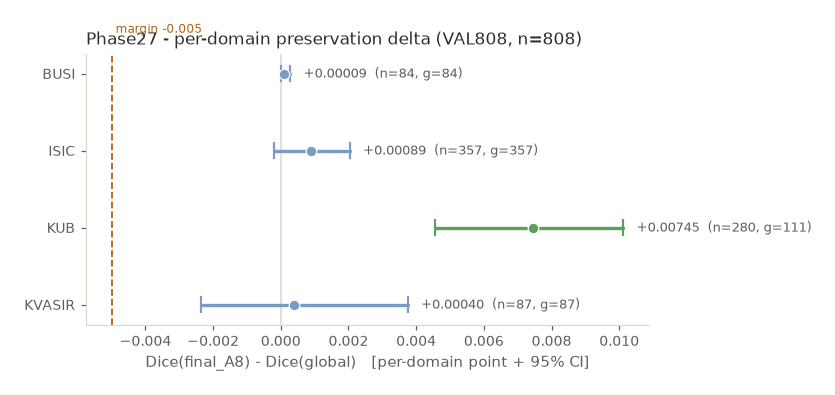

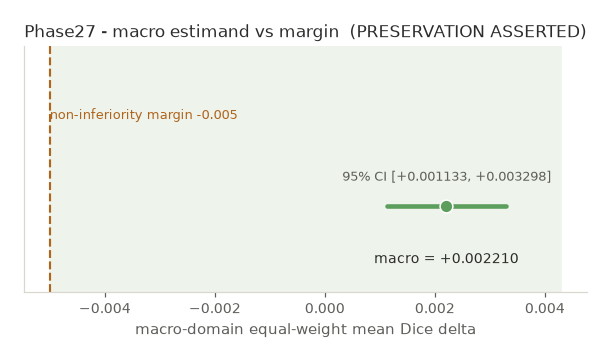

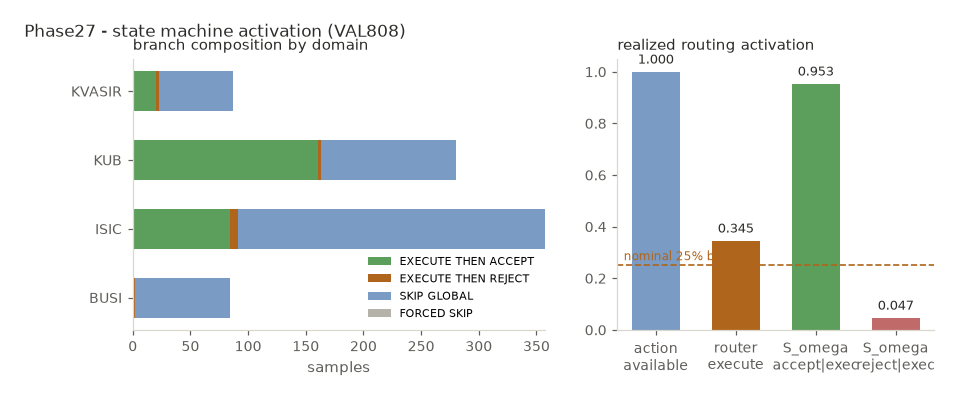

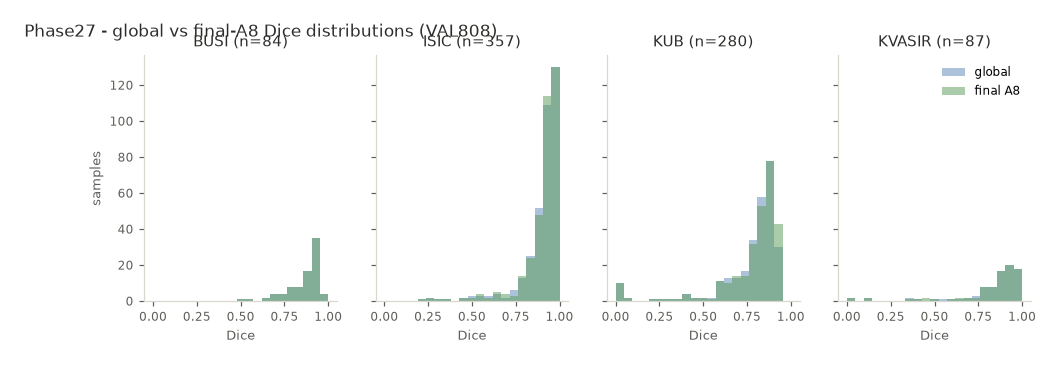

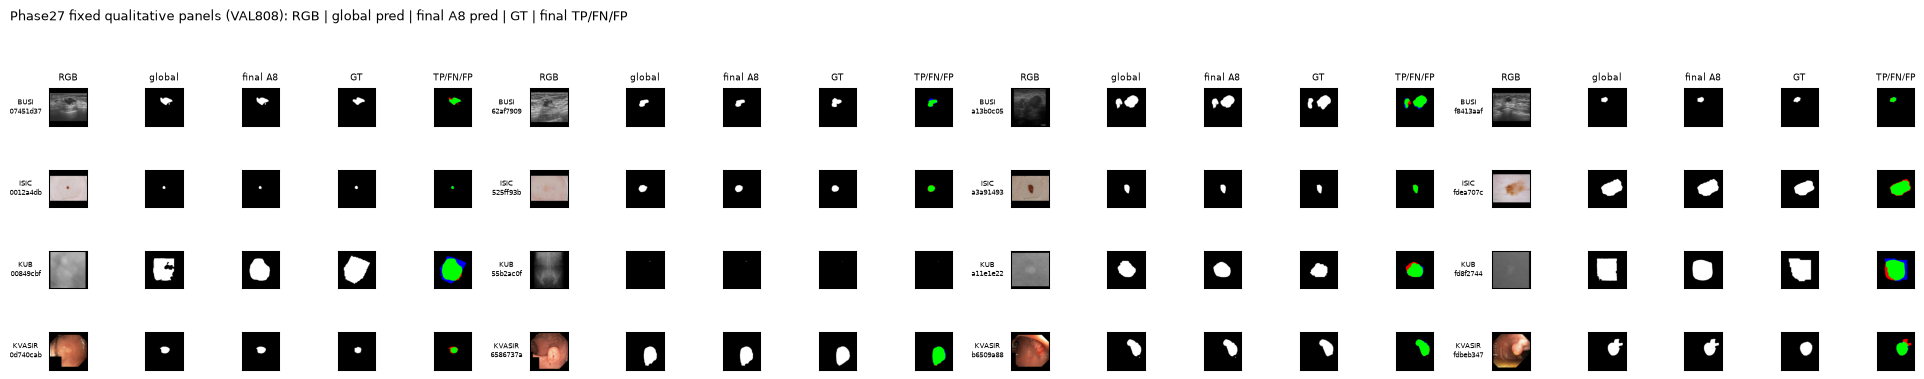

In [34]:
from IPython.display import Image, display
for f in ["p27_domain_delta_forest.png", "p27_macro_ci_vs_margin.png",
          "p27_state_machine_activation.png", "p27_dice_distributions.png",
          "p27_qualitative_panels.png"]:
    p = FIG / f
    assert p.exists(), f"missing figure {f}"
    display(Image(filename=str(p)))